# HeST Trace Event Viewer

Interactive viewer for traces from `hest_trace_generation.py`. Loads events on demand — no bulk loading.

All functionality lives in the `EventLoader` class in `event_viewer_funcs.py`.

In [1]:
%matplotlib inline

import event_viewer_funcs as EVF

In [2]:
# --- USER CONFIG ---
#TRACE_PATH = '../outputs/continuous_I9_D20261104_T111430/'
TRACE_PATH = '../outputs/continuous_I9_D20261104_T114752/'
HEST_H5_PATH = '../inputs/Spectrum_Mono_ER_energyMin_5900_energyMax_5900_nEvents_10000_seed_42069_HeraldLBNL_TopOnly.h5'
FS = 1.25e6

In [3]:
loader = EVF.EventLoader(TRACE_PATH, hest_h5=HEST_H5_PATH, fs=FS)
n_events = len(loader)
n_channels = loader.n_channels
print(f'{n_events} events, {n_channels} channels (loaded on demand)')

if loader.hest_data is not None:
    n_sensors_hest = int(loader.hest_data.attrs['n_sensors'])
    print(f'HeST truth: {loader.hest_data.attrs["n_events"]} events, {n_sensors_hest} sensors')

100 events, 4 channels (loaded on demand)
HeST truth: 10000 events, 4 sensors


## All channels

/home/dkodroff/miniforge3/envs/pythonstandard/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


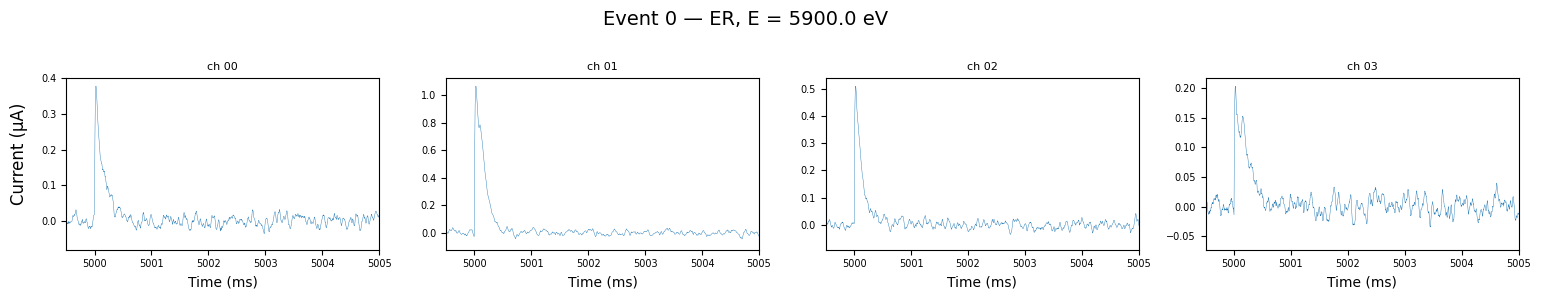

In [4]:
event_idx = 0
loader.plot_all_channels(event_idx, ds_factor=1, xlim=(4999.5, 5005))

## Single sensor with truth hits

Event 1: ER recoil, E = 5900.00 eV
Sensor 0:
  Channel     #hits  E_tot (eV)  t_mean (µs)  t_min (µs)  t_max (µs)
  ------------------------------------------------------------------
  singlet         4     64.0000         0.00        0.00        0.00
  triplet         1     16.0000      9705.88     9705.88     9705.88
  ir             10      8.5000         0.00        0.00        0.01
  qp             71     21.8215       216.38      102.45     1199.41


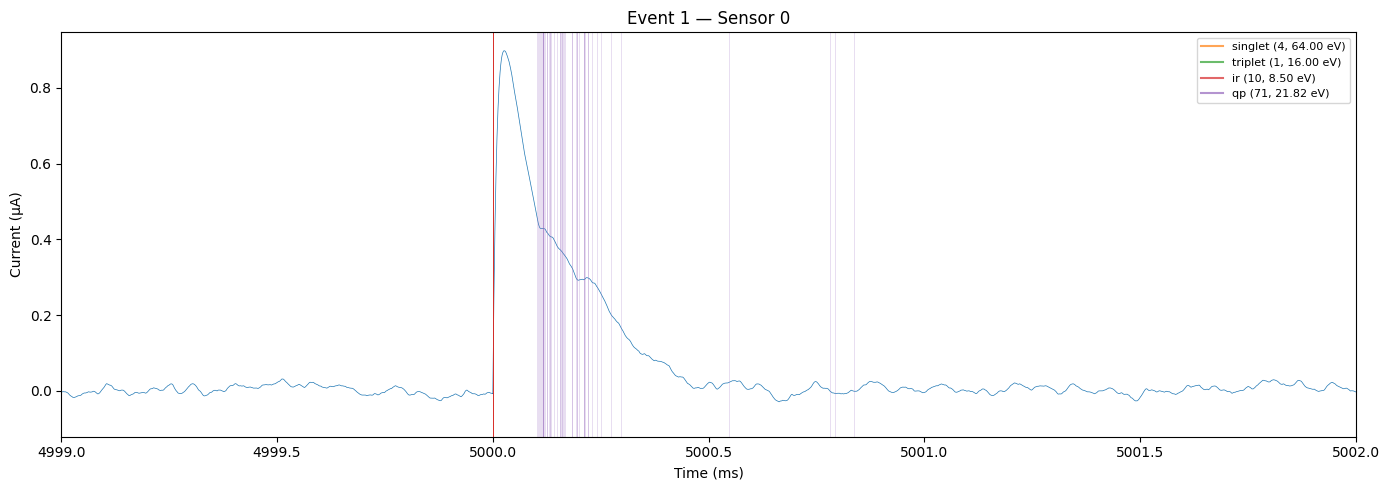

In [5]:
event_idx = 1
sensor_idx = 0
loader.plot_sensor_with_truth(event_idx, sensor_idx, xlim=(4999, 5002))

## Sensor amplitudes

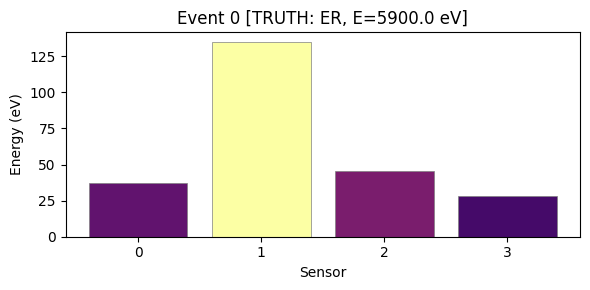

In [6]:
loader.plot_heatmap(0, use_truth=True)